# Keypoint estimation — look at your data first

Most failed projects fail here, not in the model. Before training anything, answer:
1. **Which keypoints are labelled, and are they visible?** (hidden points teach the model to guess)
2. **Where in the image do the keypoints fall?** (the spread of positions sets how much the model must generalise)
3. **Is the keypoint order consistent?** ("left" must always mean the same thing — a swap poisons training)

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/keypoints/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("keypoints", cfg)
print("task:", "keypoints", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: keypoints | data: data/demo/keypoints | outputs: outputs/keypoints_quick


## How the data is organised
COCO keypoints: `annotations.json` with `categories[0]["keypoints"]` = the point names and, per object, `keypoints: [x1, y1, v1, x2, y2, v2, …]` where `v` is 0 not labelled · 1 labelled but hidden · 2 visible. **One object per image.**

## Where do the keypoints fall?
Every keypoint of every image, normalised to the image frame. A tight cluster means the model can lean on position; a wide spread means it must really look.

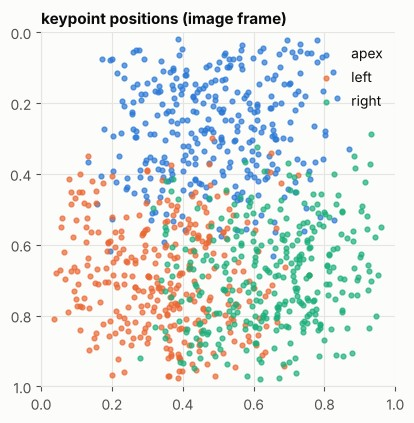

{'apex': '100% labelled', 'left': '100% labelled', 'right': '100% labelled'}


In [3]:
from tasks.keypoints.data import build_datasets

ds = build_datasets(cfg)
names, items = ds["keypoint_names"], ds["items"]

import numpy as np
import matplotlib.pyplot as plt
from cvkit.viz import CLASS_COLORS

fig, ax = plt.subplots(figsize=(4.6, 4.6))
for k, name in enumerate(names):
    xy = np.array([[it["keypoints"][3 * k] / it["width"], it["keypoints"][3 * k + 1] / it["height"]] for it in items])
    ax.scatter(xy[:, 0], xy[:, 1], s=12, color=CLASS_COLORS[k], alpha=0.7, label=name)
ax.set_xlim(0, 1); ax.set_ylim(1, 0); ax.set_aspect("equal"); ax.legend(frameon=False, loc="upper right")
ax.set_title("keypoint positions (image frame)")
plt.show()
vis = np.array([[it["keypoints"][3 * k + 2] for k in range(len(names))] for it in items])
print({n: f"{(vis[:, k] > 0).mean():.0%} labelled" for k, n in enumerate(names)})

## The model's training target: heatmaps
Instead of regressing (x, y) directly, the network predicts one *heatmap* per keypoint — an image that glows where that point probably is — and we read the position off the brightest pixel. Each heatmap below is the target the model learns for one keypoint.

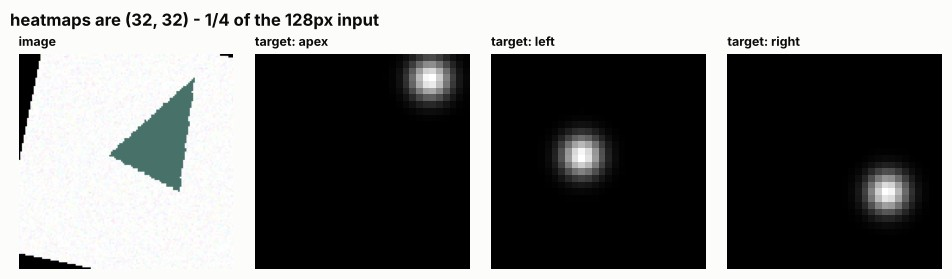

In [4]:
import torch
from cvkit.data import denormalize
from cvkit.viz import image_grid
from tasks.keypoints.model import make_heatmaps

image, points, visible = ds["train"][0]
size = cfg["data"]["image_size"]
hm = make_heatmaps(points[None], visible[None].float(), size, cfg["model"]["heatmap_sigma"])[0]
_ = image_grid([denormalize(image)] + [hm[k] for k in range(len(names))], ["image"] + [f"target: {n}" for n in names], cols=len(names) + 1, cell=2.4,
               suptitle=f"heatmaps are {tuple(hm.shape[1:])} - 1/4 of the {size}px input")

## Augmentation
Rotation, shift and zoom move the keypoints **together with the pixels** (torchvision's v2 transforms handle that). There are deliberately **no flips**: a mirrored face swaps "left eye" and "right eye", so the labels would be wrong unless you also swap them. A point pushed out of the frame is marked *not visible* and ignored.

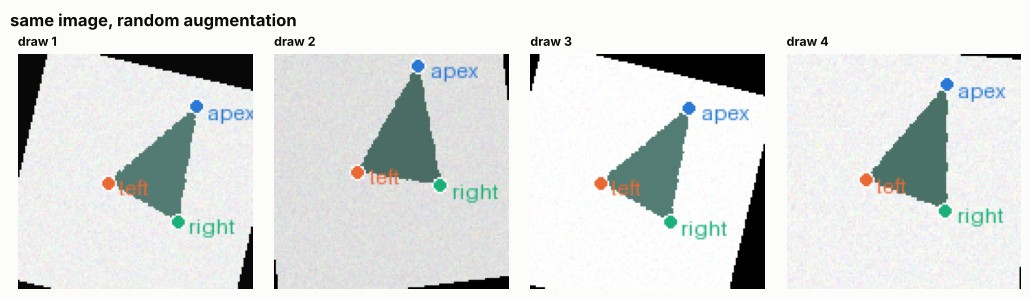

In [5]:
from tasks.keypoints.data import build_datasets
from cvkit.data import denormalize
from cvkit.viz import draw_keypoints, image_grid
from torchvision.transforms.functional import to_pil_image

train_ds = build_datasets(cfg)["train"]
shown = []
for i in range(4):
    img, pts, vis = train_ds[0]
    shown.append(draw_keypoints(to_pil_image(denormalize(img).permute(2, 0, 1)), pts.numpy(), names, visible=vis.tolist()))
_ = image_grid(shown, [f"draw {i + 1}" for i in range(4)], cols=4, cell=2.6, suptitle="same image, random augmentation")

## What the model will actually receive
One batch from the training loader, exactly as `train()` gets it:

In [6]:
from tasks.keypoints.data import build_loaders

loaders = build_loaders(cfg)
images, points, visible = next(iter(loaders["train"]))
print("images:", tuple(images.shape), "| keypoints:", tuple(points.shape), "(batch, K, x/y) in resized pixels | visible:", tuple(visible.shape), visible.dtype)

images: (16, 3, 128, 128) | keypoints: (16, 3, 2) (batch, K, x/y) in resized pixels | visible: (16, 3) torch.bool


## Before moving on
- [ ] Keypoint names and order are consistent across all images
- [ ] The points sit on the landmarks (draw them and look)
- [ ] You know which keypoints are often hidden
- [ ] `image_size` is a multiple of 4 and large enough for the precision you need

Next: **[02_train_and_evaluate](02_train_and_evaluate.ipynb)**.